In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from scipy.stats import pearsonr
import smarts_cerebellum.globals as gl

wm = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_WM', 'summary_MNISymC_CST_WM_mod.tsv'), sep = '\t')
wm['hemisphere'] = wm.regionname.str[0].astype(str).str.upper()
wm = wm[wm.isPatient == 1] # just patients


# NORMALISE AFFECTED VOLUME BY UNAFFECTED VOLUME - wm (affected = ipsi i.e. right)
wm['regionname_bilat'] = wm.regionname.str[-3:]
left_wm = wm[wm.hemisphere == 'L'][['subj_id', 'Week', 'region', 'regionname', 'regionname_bilat', 'mean']].rename(columns = {'mean': 'left_mean'})
right_wm = wm[wm.hemisphere == 'R'][['subj_id', 'Week', 'region', 'regionname', 'regionname_bilat', 'mean']].rename(columns = {'mean': 'right_mean'})
norm_wm = left_wm.merge(right_wm, on = ['subj_id', 'Week', 'regionname_bilat'], suffixes = ('_left', '_right'))

# normalise contralesional (affected) side by unaffected side; analogous to Jing's behav norm
norm_wm['right_norm'] = norm_wm['right_mean']/norm_wm['left_mean']


# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')
dti = dti[dti.isPatient == 1] # just patients
dti = dti[dti.Week == 0]

# normalize DTI metrics
dti.loc[dti.side == 'ipsilesional', 'ratio' ] = dti.loc[dti.side == 'ipsilesional', 'mean'].values /  dti.loc[dti.side == 'contralesional', 'mean'].values
dti = dti[(dti.regionname == 'CST_R') & (dti.metric == 'FaMap')] # W0 FA as measure of integrity of affected CST

dti_wm = pd.merge(dti, norm_wm, on = ['subj_id'], suffixes = ('_dti', '_wm'))

/localscratch/tmp/ipykernel_35114/876916650.py:25: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')


week 0: r = 0.37477426175385764, p-value = 0.05409152283532803
week 4: r = 0.2416557354231678, p-value = 0.278603180834795
week 12: r = 0.5707046425043775, p-value = 0.0035875989270461517
week 24: r = 0.5849646936327122, p-value = 0.0042421632479006065
week 52: r = 0.5657716961349816, p-value = 0.014393141403623872


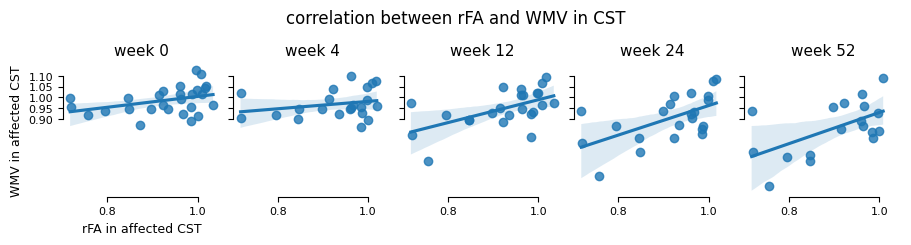

In [5]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharex = True, sharey = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    dti_wm_plot = dti_wm[(dti_wm.Week_wm== week)]
    ax = axs[i]
    sns.regplot(x = 'ratio', y = 'right_norm', data = dti_wm_plot, ax = ax)
    sns.despine(trim = True)

    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_title(f'week {week}')

    
    r_stat, p_stat = pearsonr(dti_wm_plot['ratio'], dti_wm_plot['right_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')
    
axs[0].set_ylabel("WMV in affected CST")
axs[0].set_xlabel("rFA in affected CST")
fig.suptitle(f'correlation between rFA and WMV in CST', y = 1.15)
plt.show()
